# Latihan

**Fundamen Sains Data: Latihan Bagian D**
Program Studi Informatika, Program Sarjana, Universitas Islam Indonesia

Kerjakan latihan berikut di notebook Google Colab baru. Tuliskan interpretasi setiap hasil di text cell tepat di bawah code cell yang bersangkutan, lalu jalankan **Runtime > Restart session and run all** sebelum mengumpulkan untuk memastikan notebook berjalan tanpa galat.

Notebook ini memuat **penyelesaian** kelima latihan sebagai acuan. Kerjakan sendiri terlebih dahulu sebelum membandingkan jawaban.

Seluruh latihan memakai dataset `diabetes` bawaan scikit-learn: 442 pasien dengan 10 fitur yang sudah distandardisasi dan target berupa ukuran perkembangan penyakit satu tahun kemudian.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaluasi(y_asli, y_prediksi):
    """Mengembalikan MAE, MSE, RMSE, dan R2 dalam bentuk dictionary."""
    mse = mean_squared_error(y_asli, y_prediksi)
    return {"MAE": float(mean_absolute_error(y_asli, y_prediksi)),
            "MSE": float(mse),
            "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_asli, y_prediksi))}


diabetes = load_diabetes(as_frame=True)
data = diabetes.frame          # 10 fitur + kolom 'target'
data.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


---
## Latihan 1: Eksplorasi dataset diabetes

Tampilkan ukuran data dan statistik deskriptif kolom `bmi` dan `target`, lalu buat *scatter plot* `bmi` terhadap `target`. Jelaskan bentuk hubungannya dalam satu atau dua kalimat.

*Hasil yang diharapkan:* ukuran data (442, 11) dan grafik yang menunjukkan hubungan positif.

Ukuran data: (442, 11)
           bmi   target
count  442.000  442.000
mean    -0.000  152.133
std      0.048   77.093
min     -0.090   25.000
25%     -0.034   87.000
50%     -0.007  140.500
75%      0.031  211.500
max      0.171  346.000


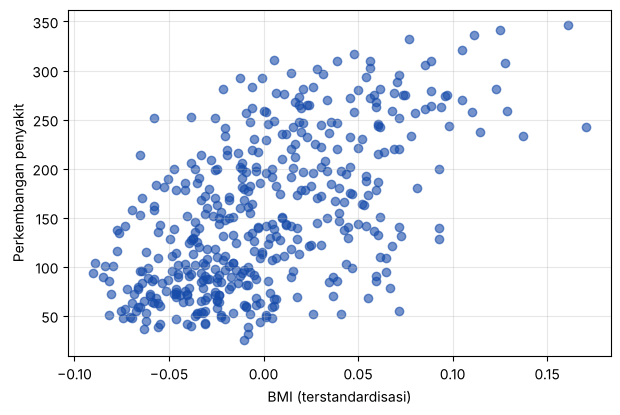

In [2]:
print("Ukuran data:", data.shape)
print(data[["bmi", "target"]].describe().round(3))

plt.figure(figsize=(7, 4.5))
plt.scatter(data["bmi"], data["target"], color="#174CAA", alpha=0.6)
plt.xlabel("BMI (terstandardisasi)")
plt.ylabel("Perkembangan penyakit")
plt.grid(alpha=0.3)
plt.show()
# Hubungannya positif dan kira-kira linier, tetapi titik-titiknya cukup menyebar.

**Penjelasan.** Data berisi 442 pasien dan 11 kolom (10 fitur dan kolom `target`). Titik-titik pada diagram pencar naik dari kiri bawah ke kanan atas, sehingga hubungan BMI dengan perkembangan penyakit **positif** dan kira-kira linier, tetapi sebarannya cukup lebar. Artinya BMI berkaitan dengan target, namun tidak cukup untuk memprediksinya secara akurat sendirian.

---
## Latihan 2: Melatih model dengan fitur bmi

Dengan fitur `bmi` saja, bagi data menjadi 80% latih dan 20% uji (`random_state=42`). Latih `LinearRegression`, lalu cetak intersep dan kemiringannya.

*Hasil yang diharapkan:* kemiringan positif yang besar (sekitar 1000) karena fitur sudah distandardisasi ke rentang kecil.

In [3]:
X_bmi = data[["bmi"]]
y_d = data["target"]
Xb_train, Xb_test, yd_train, yd_test = train_test_split(X_bmi, y_d, test_size=0.2, random_state=42)

model_bmi = LinearRegression().fit(Xb_train, yd_train)
print(f"Intersep  : {model_bmi.intercept_:.2f}")
print(f"Kemiringan: {model_bmi.coef_[0]:.2f}")

Intersep  : 152.00
Kemiringan: 998.58


**Penjelasan.** Intersep sekitar 152 sama dengan rata-rata target, karena fitur `bmi` sudah distandardisasi sehingga rata-ratanya mendekati nol. Kemiringan sekitar 998,6 tampak besar karena satu satuan `bmi` terstandardisasi mencakup rentang yang sangat lebar; kenaikan `bmi` sebesar 0,01 menaikkan prediksi sekitar 10 satuan target.

---
## Latihan 3: Evaluasi model pada data uji

Hitung MAE, RMSE, dan $R^2$ model Latihan 2 pada data uji menggunakan fungsi `evaluasi()` yang didefinisikan di awal notebook ini. Tafsirkan nilai RMSE dan $R^2$ yang diperoleh.

*Hasil yang diharapkan:* $R^2$ data uji sekitar 0,2, artinya BMI saja hanya menjelaskan sebagian kecil variasi target.

In [4]:
hasil_bmi = evaluasi(yd_test, model_bmi.predict(Xb_test))
print({k: round(v, 3) for k, v in hasil_bmi.items()})
# RMSE sekitar 64: prediksi rata-rata meleset sekitar 64 satuan target.
# R2 sekitar 0,23: BMI saja hanya menjelaskan sebagian kecil variasi perkembangan penyakit.

{'MAE': 52.26, 'MSE': 4061.826, 'RMSE': 63.732, 'R2': 0.233}


**Penjelasan.** RMSE sekitar 63,7 berarti prediksi rata-rata meleset sekitar 64 satuan target, cukup besar dibandingkan simpangan baku target (sekitar 77). Nilai $R^2$ sekitar 0,23 menunjukkan BMI saja hanya menjelaskan sekitar 23% variasi perkembangan penyakit pada data uji. Model sederhana ini memerlukan fitur tambahan agar prediksinya lebih baik.

---
## Latihan 4: Membandingkan fitur bmi dan s5

Ulangi Latihan 2 dan 3 dengan fitur `s5` sebagai pengganti `bmi` (gunakan pembagian data yang sama). Fitur mana yang menghasilkan model lebih baik? Dasarkan jawaban pada metrik data uji.

In [5]:
X_s5 = data[["s5"]]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_s5, y_d, test_size=0.2, random_state=42)
model_s5 = LinearRegression().fit(Xs_train, ys_train)

perbandingan = pd.DataFrame({
    "bmi": evaluasi(yd_test, model_bmi.predict(Xb_test)),
    "s5": evaluasi(ys_test, model_s5.predict(Xs_test))}).round(3)
print(perbandingan)
# Fitur dengan RMSE lebih kecil dan R2 lebih besar pada data uji adalah fitur yang lebih baik.

           bmi        s5
MAE     52.260    46.201
MSE   4061.826  3270.594
RMSE    63.732    57.189
R2       0.233     0.383


**Penjelasan.** Pada data uji, model dengan fitur `s5` menghasilkan MAE dan RMSE yang lebih kecil (RMSE sekitar 57,2 dibanding 63,7) serta $R^2$ yang lebih besar (sekitar 0,38 dibanding 0,23). Jadi `s5` adalah prediktor tunggal yang lebih baik daripada `bmi` untuk data ini. Perbandingan sah karena keduanya memakai pembagian data yang sama (`random_state=42`).

---
## Latihan 5: Menghitung koefisien OLS secara manual

Hitung kemiringan dan intersep model `bmi` secara manual dengan Persamaan 1 dan 2 pada Bagian D.2 menggunakan NumPy pada data latih Latihan 2. Bandingkan hasilnya dengan `model_bmi`.

*Hasil yang diharapkan:* nilai yang sama dengan `model_bmi` hingga beberapa angka desimal.

In [6]:
xm = Xb_train["bmi"].to_numpy()
ym = yd_train.to_numpy()
b1_m = np.sum((xm - xm.mean()) * (ym - ym.mean())) / np.sum((xm - xm.mean()) ** 2)
b0_m = ym.mean() - b1_m * xm.mean()
print(f"Manual          : b0 = {b0_m:.4f}, b1 = {b1_m:.4f}")
print(f"LinearRegression: b0 = {model_bmi.intercept_:.4f}, b1 = {model_bmi.coef_[0]:.4f}")

Manual          : b0 = 152.0034, b1 = 998.5777
LinearRegression: b0 = 152.0034, b1 = 998.5777


**Penjelasan.** Koefisien hasil Persamaan 1 dan 2 sama persis dengan hasil `LinearRegression` hingga empat angka desimal. Hal ini menunjukkan bahwa `LinearRegression` menghitung koefisien kuadrat terkecil (OLS) secara langsung, bukan dengan pendekatan iteratif.